# Oxidation-state inference (P1)

The P1 guesser assigns oxidation states from a composition and the coordination environments of its cations. It
needs no DFT and no bond valences, so it works on the (de)lithiated compositions whose structures are unknown.

1. **Candidates.** pymatgen enumerates every charge-balanced assignment of the composition. Some states are fixed
   by rule: O at −2 in oxides; Li, Na, Mg, F and similar at their only common state; P at +5 when every P site
   bonds only to O.
2. **Score.** Each candidate is scored with ICSD statistics of how often an element in a given state sits in a
   given environment: P(ox | env, el) = P(env | ox, el) P(ox | el) / P(env | el). The score is the geometric mean
   over the cation environments, weighted by site count.
3. **Pick.** The highest-scoring candidate wins.

An element with a fractional average state (Mn 2.29+) is scored by its best split over its sites into the two
adjacent integers (Mn3+ in some environments, Mn2+ in others).

In [1]:
%matplotlib inline
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
# Folder holding the data release (Li/, Na/, ..., models/). Set ION_INSERTION_MODELING_DATA to use another place.
DATA = Path(os.environ.get("ION_INSERTION_MODELING_DATA", "../release"))

In [2]:
from ion_insertion_modeling import oxi_state_inference as oxi

## 1. The statistics: P(ox | el) and P(ox | env, el)

In [3]:
rows = []
for el in ("Fe", "Mn", "Co", "V"):
    t = oxi.element_table(el)
    for ox in sorted(t.oxidation_state):
        if 0 < ox <= 7:
            rows.append({"element": el, "ox": int(ox), "P(ox|el)": oxi.p_ox(el, ox),
                         "P(ox|O:6,el)": oxi.p_ox_given_env(el, ox, "O:6"),
                         "P(ox|T:4,el)": oxi.p_ox_given_env(el, ox, "T:4")})
probs = pd.DataFrame(rows)
probs.round(3)

,element,ox,P(ox|el),"P(ox|O:6,el)","P(ox|T:4,el)"
0,Fe,1,0.002,0.000,0.000
1,Fe,2,0.273,0.219,0.127
2,Fe,3,0.690,0.761,0.758
3,Fe,4,0.023,0.021,0.043
4,Fe,5,0.002,0.000,0.014
5,Fe,6,0.009,0.000,0.058
6,Mn,2,0.461,0.410,0.529
7,Mn,3,0.273,0.261,0.033
8,Mn,4,0.225,0.328,0.022
9,Mn,5,0.021,0.000,0.219


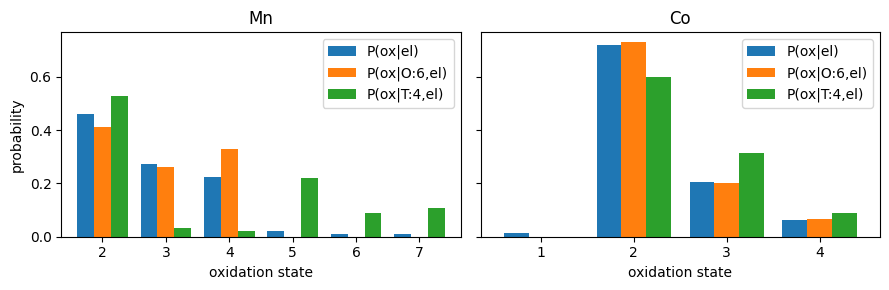

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, el in zip(axes, ("Mn", "Co")):
    p = probs[probs.element == el].set_index("ox")[["P(ox|el)", "P(ox|O:6,el)", "P(ox|T:4,el)"]]
    p.plot.bar(ax=ax, rot=0, width=0.8)
    ax.set_title(el); ax.set_xlabel("oxidation state"); ax.set_ylabel("probability")
plt.tight_layout()

Environment matters: tetrahedral Mn is mostly Mn2+ (or Mn5+, Mn6+, Mn7+ oxo-anions), octahedral Mn mostly Mn3+/Mn4+.
ChemEnv symbols: O:6 octahedron, T:4 tetrahedron, C:8 cube, S:4 square plane, etc.

## 2. Scoring a composition with known environments

LiFePO4: Fe in octahedra, P in tetrahedra (4 of each per cell). Every candidate is listed with its score:

In [5]:
envs = [("Fe", "O:6", 4), ("P", "T:4", 4)]
g = oxi.guess_from_environments("LiFePO4", envs, fixed={"P": 5})
print(g)
pd.DataFrame([{**states, "score": s} for states, s in g.candidates])

OxiGuess(states={'Li': 1.0, 'P': 5.0, 'O': -2.0, 'Fe': 2.0}, score=0.4676921368096763, fixed={'Li': 1, 'O': -2, 'P': 5}, scoring='P_ox_env_sites_split')


,Li,P,O,Fe,score
0,1,5,-2,2.0,0.467692


Delithiate it: the same environments, composition FePO4. Fe goes to 3+:

In [6]:
oxi.guess_from_environments("FePO4", envs, fixed={"P": 5})

OxiGuess(states={'P': 5.0, 'O': -2.0, 'Fe': 3.0}, score=0.8717314160332128, fixed={'O': -2, 'P': 5}, scoring='P_ox_env_sites_split')

## 3. Mixed valence and the per-site split

Magnetite Fe3O4 has one tetrahedral and two octahedral Fe per formula. Its average state is Fe 2.67+, scored as the
best split: Fe3+ on the tetrahedral site and Fe2+/Fe3+ on the octahedral ones. In Mn7(P2O7)4, 2 of the 14 Mn sites
are 8-coordinate, where Mn3+ was never observed. Interpolating to Mn 2.29+ on every site would give a score of 0;
the split puts Mn2+ there and Mn3+ in the octahedra.

In [7]:
for comp, e, fixed in [("Fe3O4", [("Fe", "T:4", 1), ("Fe", "O:6", 2)], None),
                       ("Mn7(P2O7)4", [("Mn", "O:6", 12), ("Mn", "C:8", 2), ("P", "T:4", 16)], {"P": 5})]:
    split = oxi.guess_from_environments(comp, e, fixed=fixed)
    plain = oxi.guess_from_environments(comp, e, fixed=fixed, scoring="P_ox_env_sites")
    print(f"{comp:12s} states {split.states}   score with split {split.score:.3f}, averaged only {plain.score:.3f}")

Fe3O4        states {'O': -2.0, 'Fe': 2.6666666666666665}   score with split 0.502, averaged only 0.472


Mn7(P2O7)4   states {'P': 5.0, 'O': -2.0, 'Mn': 2.2857142857142856}   score with split 0.659, averaged only 0.000


## 4. From a structure

`guess_from_structure` runs ChemEnv on the structure (a few seconds for small cells), then scores the candidates.
`guess_from_framework` scores *another* composition of the same framework on those environments. That is how every
(de)lithiated material is assigned without its own structure.

In [8]:
from pymatgen.core import Structure

lfp = Structure.from_file("../tests/data/LiFePO4_mp-19017.cif")
print(oxi.environments_from_structure(lfp))  # O entries are kept for reference; P1 skips them (O is fixed at -2)
print(oxi.guess_from_structure(lfp))
print(oxi.guess_from_framework("Li0.5FePO4", lfp))

[('Fe', 'O:6', 4.0), ('P', 'T:4', 4.0), ('O', 'S:1', 4.0), ('O', 'A:2', 8.0), ('O', 'T:4', 4.0)]
OxiGuess(states={'Li': 1.0, 'P': 5.0, 'O': -2.0, 'Fe': 2.0}, score=0.4676921368096763, fixed={'Li': 1, 'O': -2, 'P': 5}, scoring='P_ox_env_sites_split')
OxiGuess(states={'Li': 1.0, 'P': 5.0, 'O': -2.0, 'Fe': 2.5}, score=0.6385154099069953, fixed={'Li': 1, 'O': -2, 'P': 5}, scoring='P_ox_env_sites_split')


## 5. A disordered structure

The cation-disordered garnet Li7Pr3(Mn0.25Mo0.75)2O12 has Mn/Mo sharing octahedral sites and partly occupied Li
sites. ChemEnv counts each species of a mixed site by its occupancy; the formula is scaled to integers
(Li56Pr24Mn4Mo12O96) before candidates are enumerated. ChemEnv takes about a minute on this 208-site cell.

The CIF was written by pymatgen with oxidation states attached (Mn4+, Mo4+). Those states are only one charge-balanced
guess; P1 ignores them and decides from the environments:

In [9]:
garnet = Structure.from_file("data/disordered_Li7PrMoMnO.cif")
print("ordered:", garnet.is_ordered, "| sites:", len(garnet), "|", garnet.composition.reduced_formula)
print("states written in the CIF:", sorted({str(sp) for site in garnet for sp in site.species}))
g = oxi.guess_from_structure(garnet)
print(g)
pd.DataFrame([{**s, "score": sc} for s, sc in g.candidates[:6]]).round(3)

ordered: False | sites: 208 | Li14Pr6Mn(MoO8)3
states written in the CIF: ['Li+', 'Mn4+', 'Mo4+', 'O2-', 'Pr3+']


OxiGuess(states={'Li': 1.0, 'Pr': 3.0, 'Mn': 2.0, 'Mo': 4.666666666666667, 'O': -2.0}, score=0.5374978297881071, fixed={'Li': 1, 'O': -2}, scoring='P_ox_env_sites_split')


,Li,Pr,Mn,Mo,O,score
0,1.0,3.000,2.0,4.667,-2.0,0.537
1,1.0,3.000,3.0,4.333,-2.0,0.471
2,1.0,3.000,4.0,4.000,-2.0,0.442
3,1.0,3.167,2.0,4.333,-2.0,0.232
4,1.0,3.167,3.0,4.000,-2.0,0.203
5,1.0,3.167,4.0,3.667,-2.0,0.191


Every octahedral candidate is close (0.54, 0.47, 0.44): this composition really is ambiguous between Mn2+/Mo4.67+
and Mn4+/Mo4+. A structure-free alternative treats every cation as octahedral (`uniform_environments`), which is how
compositions without a structure (e.g. disordered rock salts) can be handled:

In [10]:
oxi.guess_from_environments(garnet.composition, oxi.uniform_environments(garnet.composition, "O:6"))

OxiGuess(states={'Li': 1.0, 'Pr': 3.0, 'Mn': 2.0, 'Mo': 4.666666666666667, 'O': -2.0}, score=0.4565441584961204, fixed={'Li': 1, 'O': -2}, scoring='P_ox_env_sites_split')

## 6. Which Li content is most plausible?

`best_ion_content` scans the Li content of a framework and returns the content whose composition gets the highest
P1 score on the structure's environments. Here x counts Li per Pr3Mo1.5Mn0.5O12 (12 O):

highest P1 score at x = 5.0 {'Li': 1.0, 'Pr': 3.0, 'Mn': 2.0, 'Mo': 6.0, 'O': -2.0}


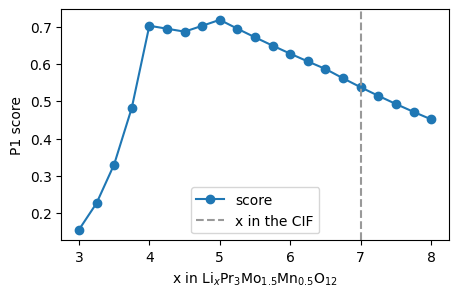

In [11]:
x_best, g_best, table = oxi.best_ion_content(garnet, x_grid=np.arange(3, 8.01, 0.25), framework_formula="Pr3Mo1.5Mn0.5O12")
print("highest P1 score at x =", x_best, g_best.states)
ax = table.plot(x="x", y="score", marker="o", legend=False, figsize=(5, 3))
ax.axvline(7, color="0.6", ls="--", label="x in the CIF")
ax.set_xlabel("x in Li$_x$Pr$_3$Mo$_{1.5}$Mn$_{0.5}$O$_{12}$"); ax.set_ylabel("P1 score"); ax.legend()

The score peaks where the oxidation states are most typical for these environments (here octahedral Mo6+ with Mn2+).
It measures how plausible the oxidation states are, not thermodynamic stability; the stable Li range comes from the
model (notebook 03). In the paper, the change in this score between the initial and (de)lithiated material
(`delta_p1_score`) is one of the strongest predictors of ΔEdecomp.